# 3. Which regular shoppers are about to go quiet?

**Population:** households that shopped in at least 8 of the last 16 weeks ("regulars").
**Target:** they shop in 2 or fewer of the next 8 weeks.
**Validation:** rolling-origin backtest. For each test week the model only sees cutoffs whose labels were
complete by then: train, then calibrate on the most recent of those, then test.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

from couponroi import config
from couponroi.warehouse import connect

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()  # read-only DuckDB warehouse built by `couponroi build`
R = lambda name: json.loads((config.RESULTS_DIR / f"{name}.json").read_text())  # noqa: E731
fig = lambda name, width=900: display(Image(filename=str(config.FIG_DIR / f"{name}.png"), width=width))  # noqa: E731
sql = lambda path: (config.SQL_DIR / path).read_text()  # noqa: E731
from sklearn.metrics import roc_auc_score
from couponroi.churn import split_for, topk_metrics
from couponroi.features import FEATURE_DESCRIPTIONS, features_at, is_regular, labels_at
from couponroi.models import LogitModel

## Choosing the target

My first target was "spend over the next 8 weeks falls below half of the last 16". It's noisy: grocery spend
swings week to week for boring reasons. This cell compares three definitions with the same features and a plain
logistic regression on the same 3 backtest folds.

In [2]:
cfg = config.SETTINGS.churn
cutoffs = cfg.cutoffs()
frames = []
for c in cutoffs:
    f = features_at(con, c)
    y = labels_at(con, c)[["household_id", "lapse", "spend_halved", "full_lapse"]]
    frames.append(f.merge(y, on="household_id"))
frame = pd.concat(frames, ignore_index=True)
frame = frame[is_regular(frame)]

rows = []
for target in ["spend_halved", "lapse", "full_lapse"]:
    for test in cfg.test_cutoffs:
        train, cal = split_for(test, cutoffs, cfg)
        tr, te = frame[frame.cutoff.isin(train + cal)], frame[frame.cutoff == test]
        p = LogitModel().fit(tr, tr[target].to_numpy()).predict(te)
        rows.append({"target": target, "test_week": test, "base_rate": te[target].mean(),
                     "roc_auc": roc_auc_score(te[target], p), **topk_metrics(te[target].to_numpy(), p, 0.1)})
pd.DataFrame(rows).groupby("target")[["base_rate", "roc_auc", "recall_at_k", "lift_at_k"]].mean()

,base_rate,roc_auc,recall_at_k,lift_at_k
target,,,,
full_lapse,0.013,0.831,0.498,4.988
lapse,0.077,0.828,0.397,3.978
spend_halved,0.149,0.705,0.230,2.302


"Regular goes quiet" is both more predictable and more useful: it's a real change in behaviour a CRM team can act
on. Full lapse (zero trips) is rarer still, about 1% of regulars, too rare to build a programme around.

## The training frame

In [3]:
frame.groupby("cutoff").agg(households=("lapse", "size"), lapse_rate=("lapse", "mean")).T.round(3)

cutoff,17,19,21,23,25,27,29,31,33,35,37,39,41,43,45
households,"1,366.000","1,381.000","1,394.000","1,402.000","1,403.000","1,415.000","1,426.000","1,417.000","1,437.000","1,435.000","1,424.000","1,428.000","1,410.000","1,421.000","1,422.000"
lapse_rate,0.051,0.064,0.070,0.073,0.068,0.064,0.068,0.070,0.079,0.070,0.072,0.076,0.080,0.085,0.080


Every feature is computed from data up to the cutoff week only. `tests/test_leakage.py` proves it: it scrambles
every row after the cutoff (spend, trips, campaigns) and checks the features don't move.

In [4]:
pd.Series(FEATURE_DESCRIPTIONS).to_frame('what it measures')

,what it measures
recency_weeks,weeks since last shopping trip
spend_4w,"avg weekly spend, last 4 weeks ($)"
spend_8w,"avg weekly spend, last 8 weeks ($)"
spend_16w,"avg weekly spend, last 16 weeks ($)"
trips_4w,trips in the last 4 weeks
trips_8w,trips in the last 8 weeks
trips_16w,trips in the last 16 weeks
active_weeks_8w,"weeks with a trip, last 8"
active_weeks_16w,"weeks with a trip, last 16"
basket_value_16w,avg spend per trip ($)


## Backtest results

In [5]:
ch = R("churn")
folds = pd.DataFrame(ch["folds"])
folds.pivot(index="model", columns="test_cutoff", values="roc_auc").round(3)

test_cutoff,37,41,45
model,,,
LightGBM,0.831,0.828,0.824
logistic regression,0.837,0.812,0.831
rule: recent spend drop,0.625,0.674,0.693


In [6]:
pd.DataFrame(ch['summary']).set_index('model')[['pr_auc', 'roc_auc', 'recall_at_k', 'lift_at_k', 'brier', 'ece']].round(3)

,pr_auc,roc_auc,recall_at_k,lift_at_k,brier,ece
model,,,,,,
LightGBM,0.265,0.828,0.362,3.628,0.063,0.014
logistic regression,0.279,0.827,0.380,3.802,0.063,0.014
rule: recent spend drop,0.224,0.664,0.298,2.987,NaN,NaN


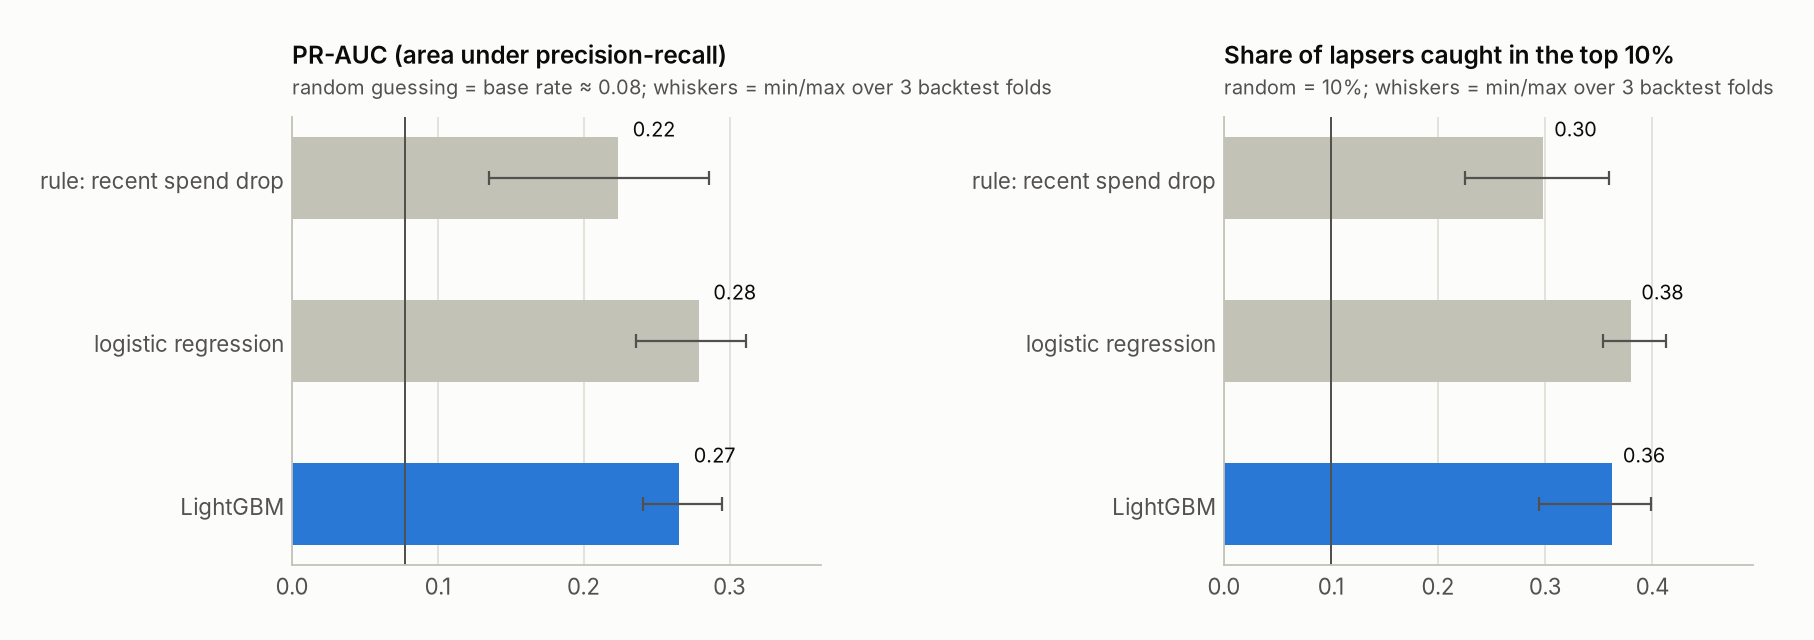

On 3 out-of-time test folds LightGBM reached PR-AUC 0.27 (base rate 0.07, ROC-AUC 0.83) and caught 36% of the regular shoppers about to go quiet in its top 10%, vs 30% for the day-one rule.

In [7]:
fig('churn_1_backtest', 1000); display(Markdown(ch['headline']))

**Honest note:** LightGBM and logistic regression are tied (differences are smaller than the fold-to-fold
swing). Both beat the day-one rule by a wide margin. The gain came from the target definition and the features,
not the algorithm. LightGBM is kept because its TreeSHAP values give per-household reasons in the app and API;
the logistic model would be a perfectly good production choice.

## Calibration

The targeting maths multiplies probabilities by dollars, so they need to mean what they say. Platt scaling is
fitted on the calibration weeks (always earlier than the test week). Isotonic regression was tried first and
overfit the sparse top end (it jumped to 100% for a few households).

In [8]:
folds[folds.model == 'LightGBM'][['test_cutoff', 'ece_uncalibrated', 'ece_isotonic', 'ece', 'platt_a', 'platt_b']]

,test_cutoff,ece_uncalibrated,ece_isotonic,ece,platt_a,platt_b
2,37,0.023,0.023,0.023,0.946,-0.145
5,41,0.015,0.009,0.007,1.118,0.360
8,45,0.015,0.014,0.012,0.992,0.069


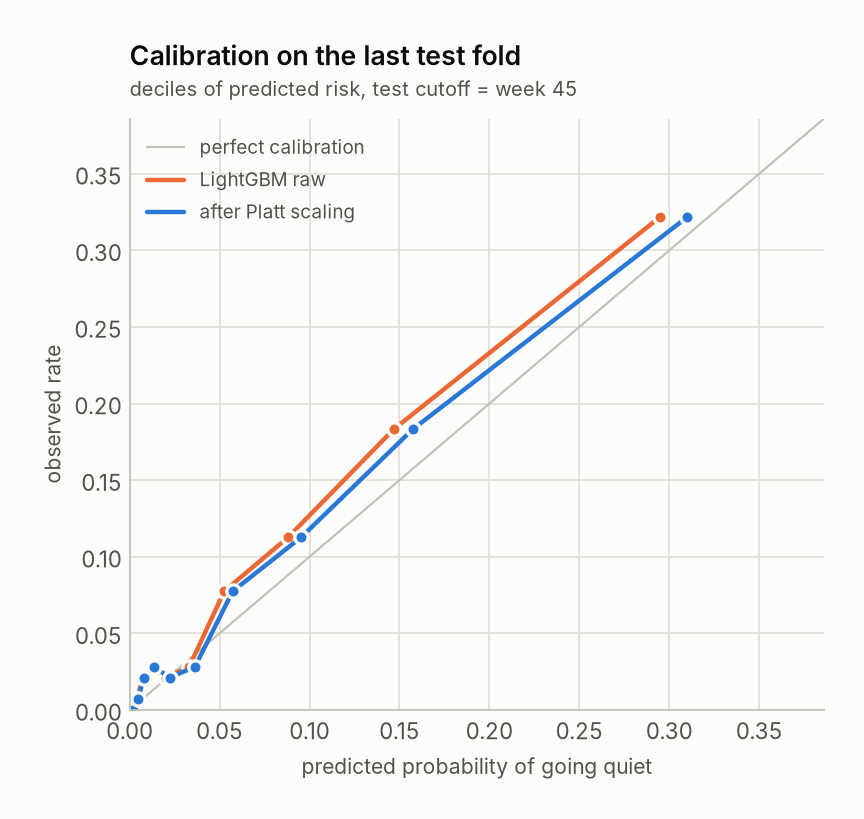

In [9]:
fig('churn_2_calibration', 520)

## What drives the risk (SHAP)

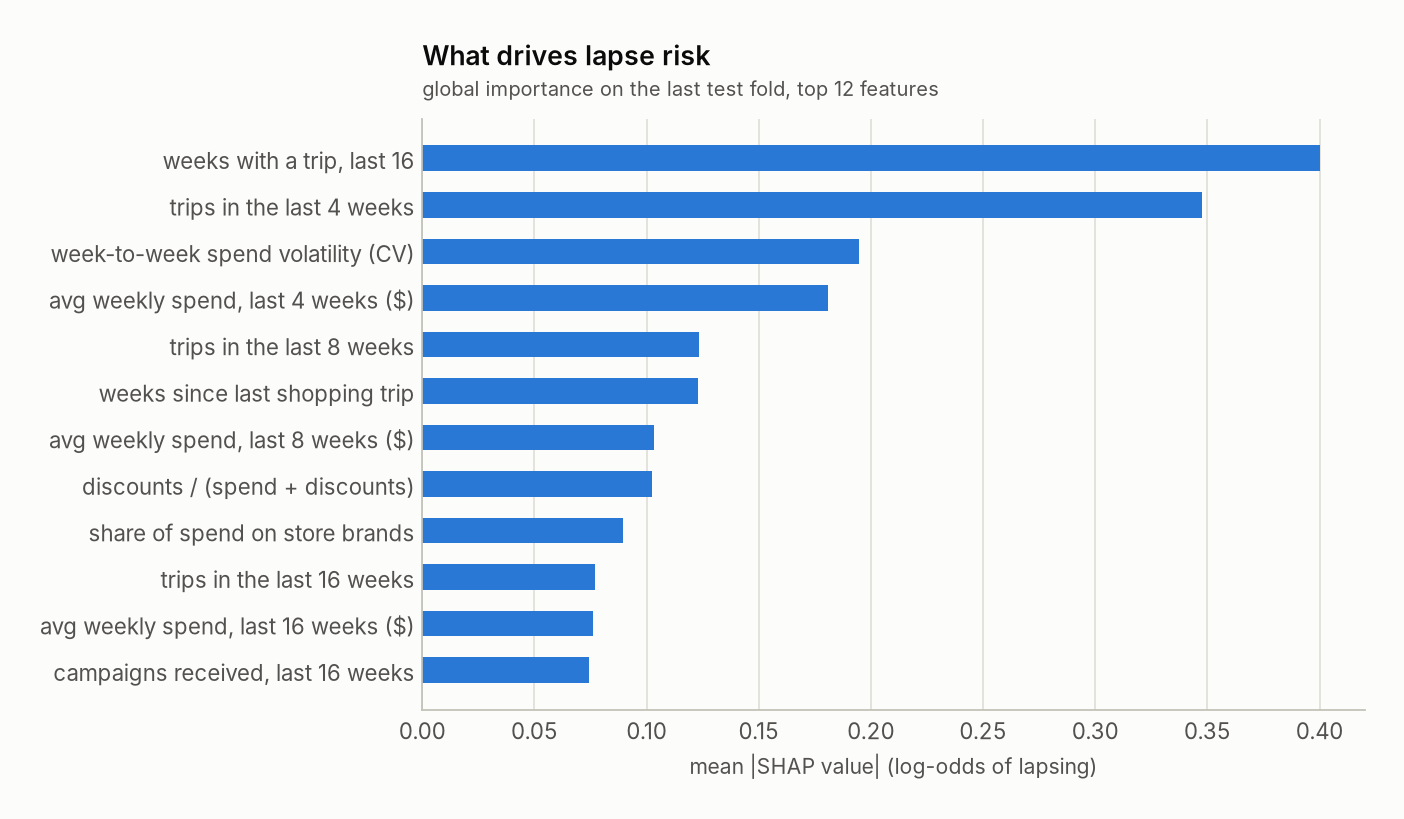

In [10]:
fig('churn_3_shap_importance', 760)

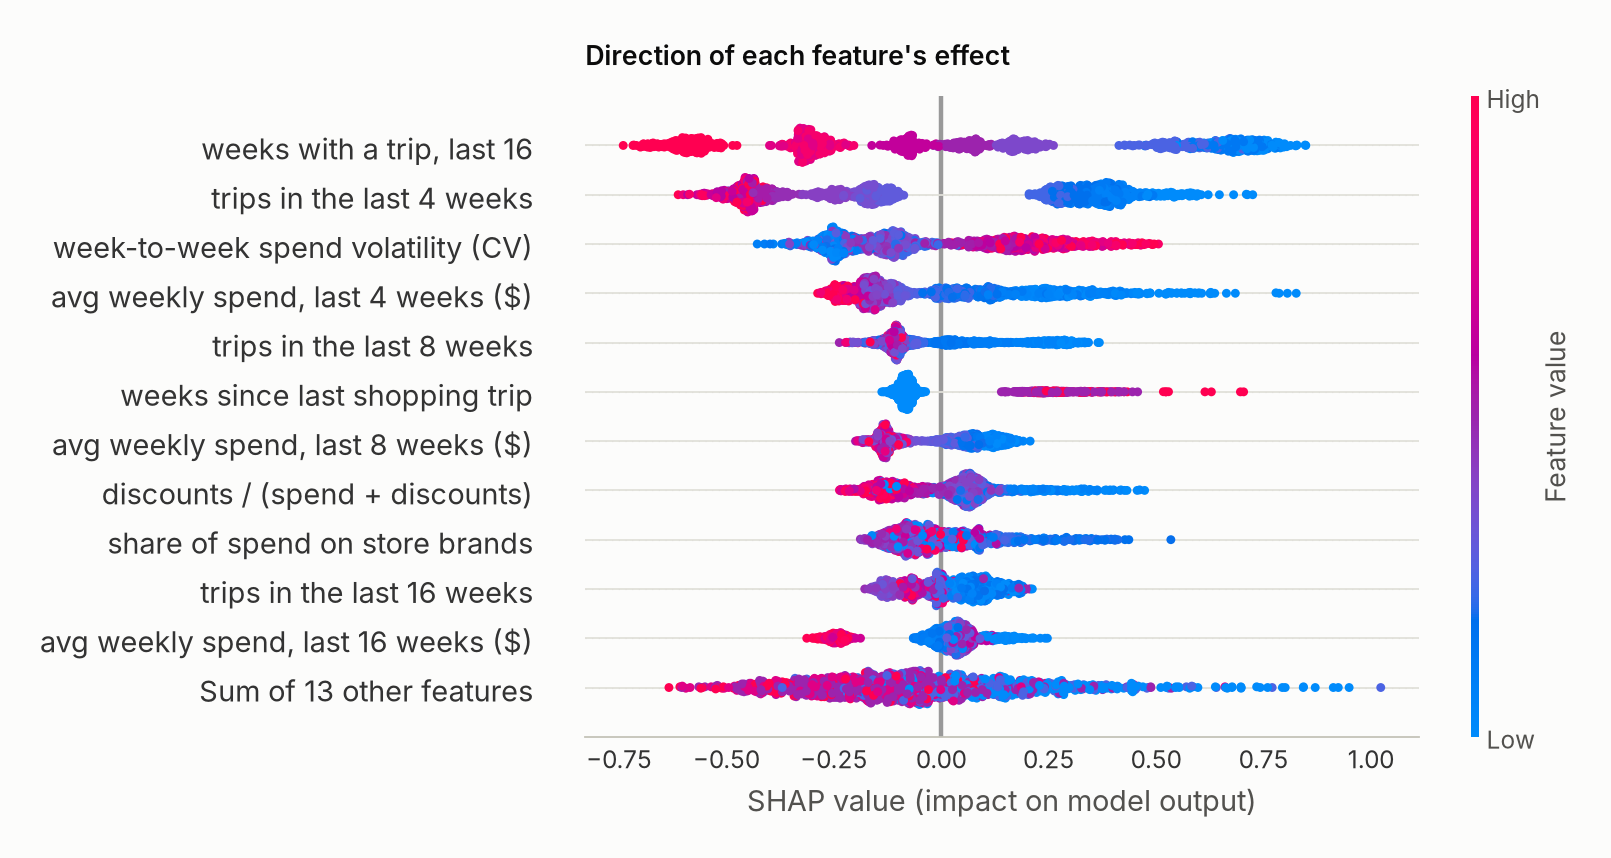

In [11]:
fig('churn_4_shap_beeswarm', 820)

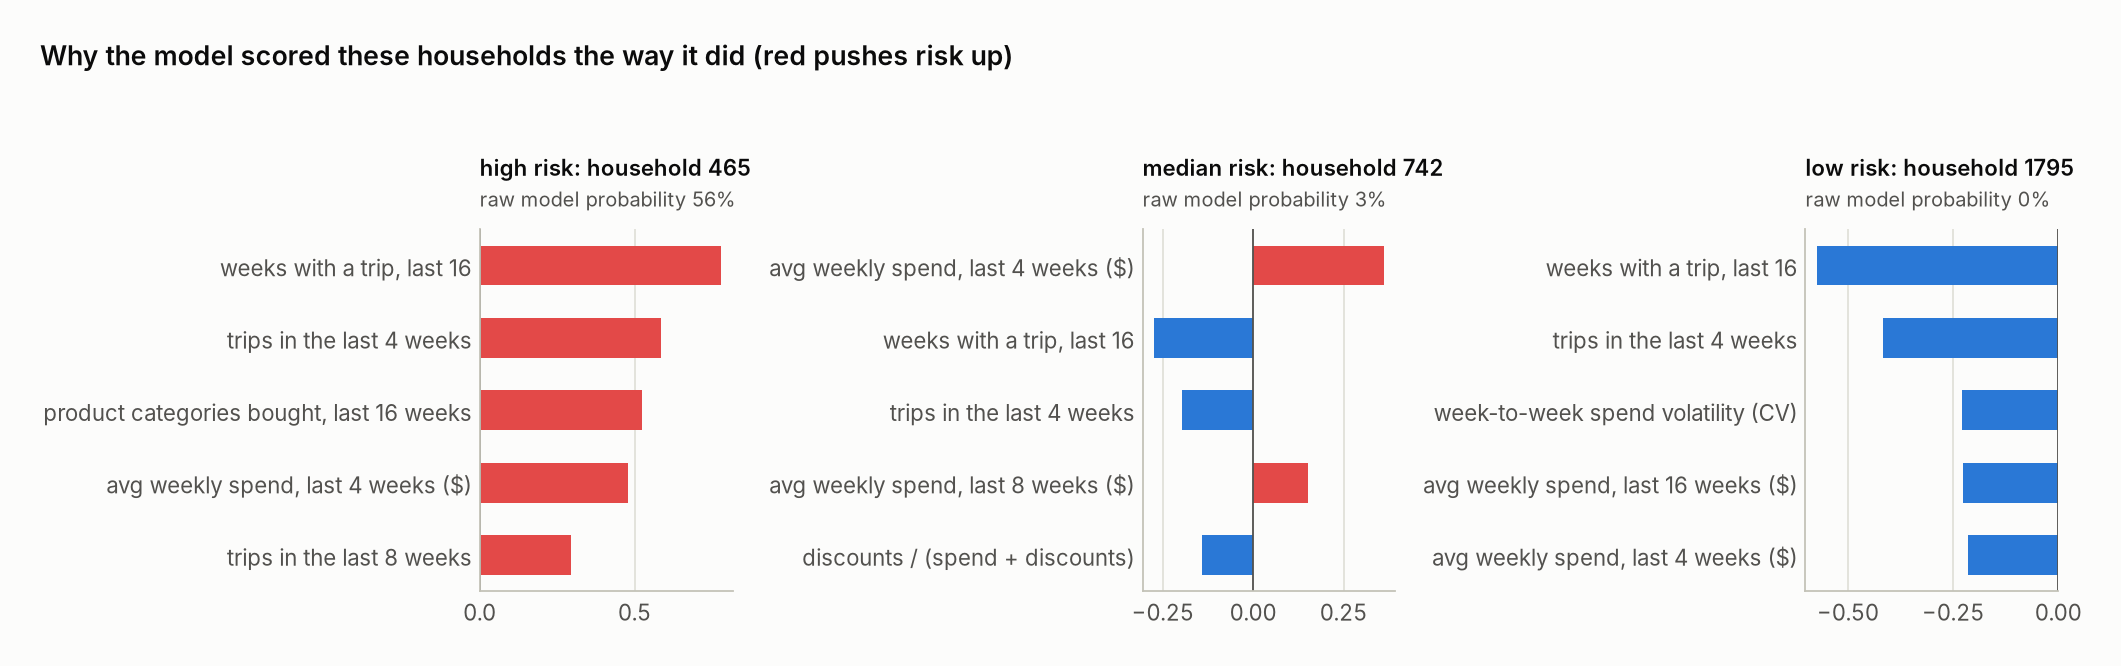

In [12]:
fig('churn_5_shap_cases', 1000)

## Drift

PSI between the first training week and the scoring week. The first version of the features had "to date"
counters (tenure, booklets received to date) that grow mechanically through the year. This check flagged them,
so every feature now uses a fixed window. What's left flagged is campaign exposure, which really did ramp up
in the second half of the year.

In [13]:
pd.DataFrame(R('drift')['table']).head(8)

,feature,psi,ref_mean,cur_mean,status
0,type_a_16w,0.983,0.214,0.686,drifted
1,campaigns_16w,0.833,0.483,1.544,drifted
2,redemptions_16w,0.291,0.079,0.650,drifted
3,spend_slope_rel_16w,0.045,-0.005,0.007,stable
4,momentum_8v16,0.032,0.981,1.023,stable
5,momentum_4v16,0.030,0.968,1.038,stable
6,promo_share_16w,0.024,0.218,0.206,stable
7,spend_cv_16w,0.024,1.010,1.032,stable


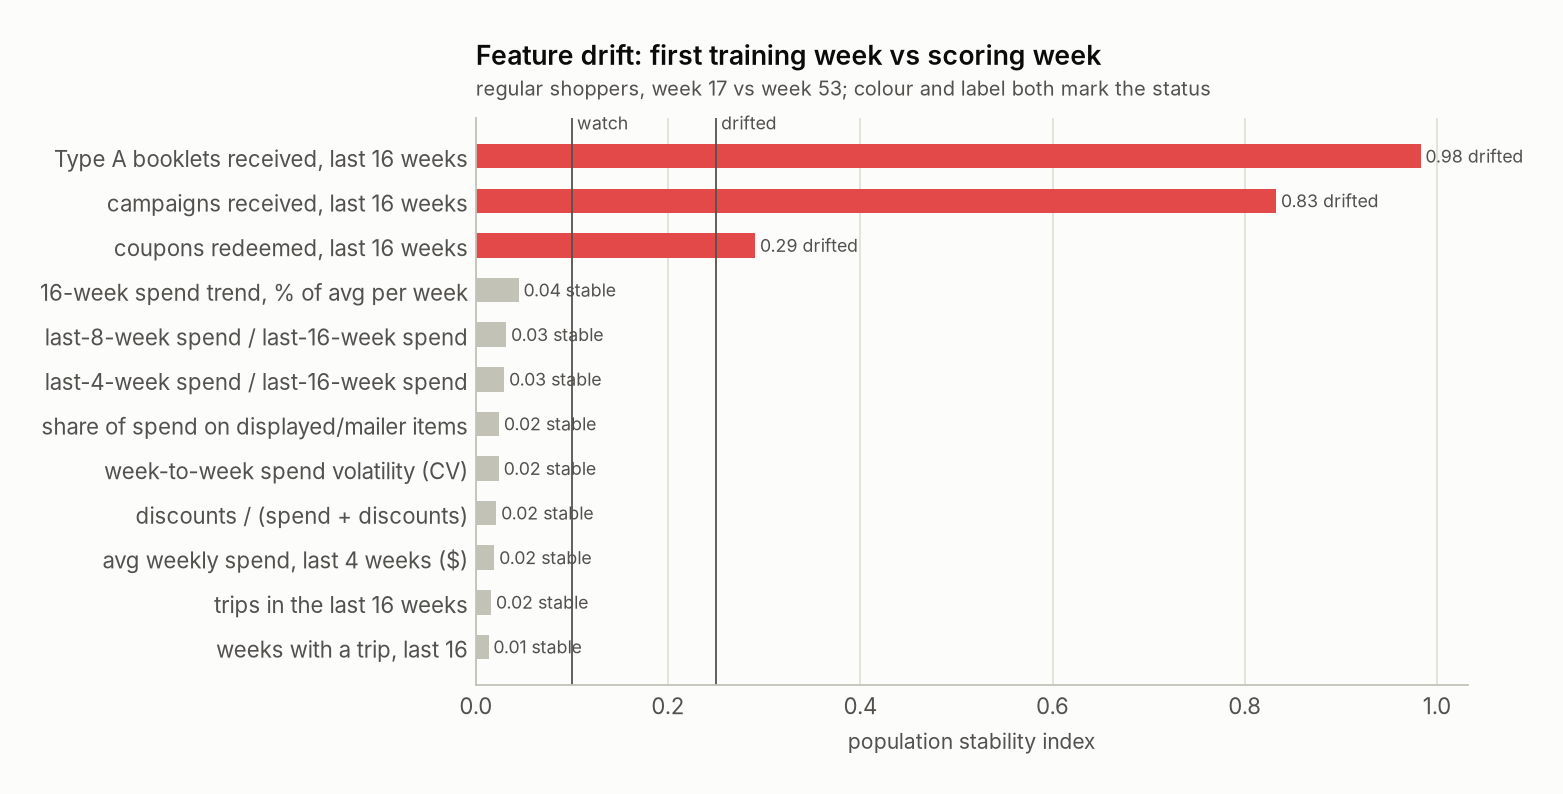

In [14]:
fig('drift_1_psi', 760)